# Этап 3. Разведочный анализ данных — СвязьРегион

Команда: Алексей, Захар. Ноутбук запускает тот же код, что `python run_eda.py`, и показывает результаты. Проверка воспроизводимости: *Restart kernel → Run all*.

**Объект:** строка «абонент × T». **T:** 00:00 МСК 1-го числа. **База:** состояние перед событиями на T — `activation < T`, расторжения нет или `termination ≥ T`. **Горизонт:** календарный месяц `[T, 1-е число следующего месяца)`. **EDA:** T 01.12.2025–01.07.2026; 01.08.2026 — валидация, 01.09.2026 — тест (в выводах не используются).

In [1]:
import sys
from pathlib import Path
sys.path.insert(0, str(Path('src').resolve()))  # ноутбук открывается из папки 3_eda
import pandas as pd
from IPython.display import Image, display
from eda.pipeline import run
from eda.sample import load_config
pd.set_option('display.width', 160); pd.set_option('display.max_columns', 30)
res = run()
OUT = load_config()['output_dir']
T = lambda name: pd.read_csv(OUT / 'tables' / f'{name}.csv', sep=';', encoding='utf-8-sig')
{k: res['summary'][k] for k in ['eda_rows', 'eda_customers', 'eda_churn', 'sample_rows_by_split', 'horizon']}

[1] eda_sample: 19541 строк, из них EDA 15696, абонентов EDA 2319


[2] таблицы и 6 рисунков сохранены
[3] проверки: все пройдены (10)
Готово: /home/claude/work/3_eda/output


{'eda_rows': 15696,
 'eda_customers': 2319,
 'eda_churn': 440,
 'sample_rows_by_split': {'eda': 15696, 'validation': 1929, 'test': 1916},
 'horizon': 'calendar_month'}

## План гипотез

In [2]:
res['plan'][['hypothesis_id', 'question', 'groups', 'result']]

,hypothesis_id,question,groups,result
0,H1,Отличается ли будущая доля ухода у абонентов с...,долг > 0 / долг = 0 / неизвестно (closing_debt...,поддерживается на EDA-периоде
1,H2,Связаны ли доступные к T обращения в поддержку...,support_count прошлого месяца: 0 / 1 / 2+ / не...,не поддерживается / связь слабая
2,H3,Меняется ли доля оттока и размер активной базы...,даты T,"поддерживается: доля растёт, база слегка сокра..."
3,H4,Различается ли отток по стажу и не объясняется...,стаж на T: <90 / ≥90 дней; проверка внутри гру...,данных недостаточно (направление: выше у <90 дн.)


## 1–2. Пропуски и распределения

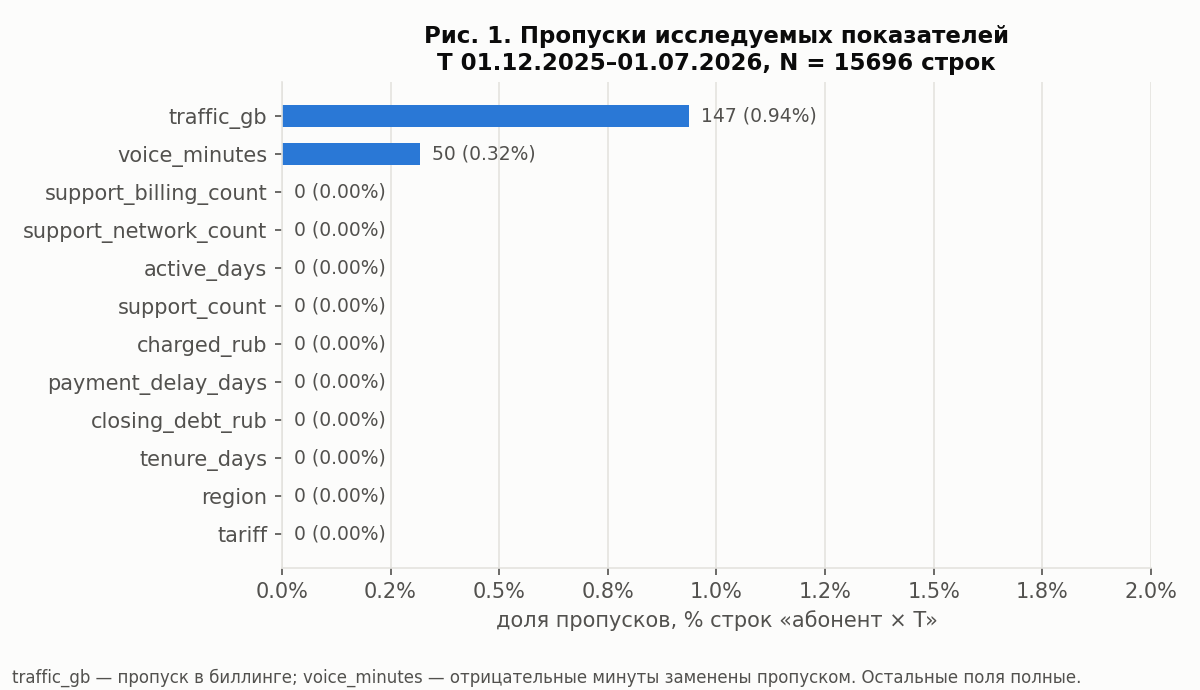

,field,n_rows,n_known,n_missing,missing_share,reason
0,tariff,15696,15696,0,0.00000,NaN
1,region,15696,15696,0,0.00000,NaN
2,tenure_days,15696,15696,0,0.00000,NaN
3,closing_debt_rub,15696,15696,0,0.00000,NaN
4,payment_delay_days,15696,15696,0,0.00000,NaN
5,charged_rub,15696,15696,0,0.00000,NaN
6,traffic_gb,15696,15549,147,0.00937,пропуск в источнике биллинга (флаг traffic_mis...
7,voice_minutes,15696,15646,50,0.00319,отрицательное значение в источнике заменено пр...
8,active_days,15696,15696,0,0.00000,NaN
9,support_count,15696,15696,0,0.00000,NaN


In [3]:
display(Image(OUT / 'figures' / 'fig1_missing.png'))
T('fig1_missing')

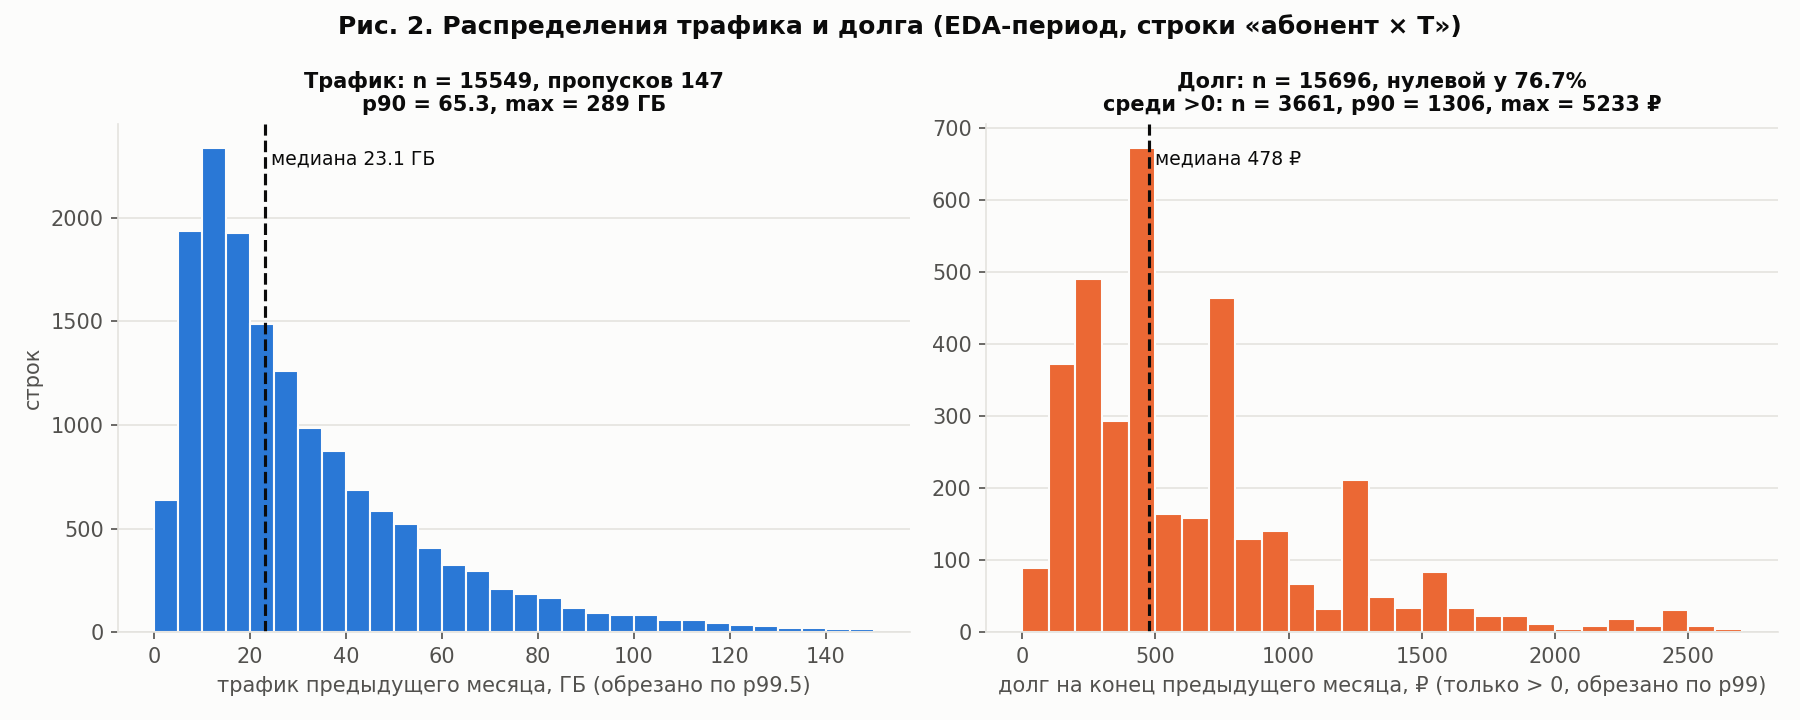

,field,n_known,n_missing,mean,p05,p25,median,p75,p90,p95,p99,max,share_zero
0,traffic_gb,15549,147,31.171,5.50,12.67,23.07,41.540,65.256,83.058,126.465,289.44,0.000
1,closing_debt_rub,15696,0,155.899,0.00,0.00,0.00,0.000,603.420,900.000,1783.500,5233.36,0.767
2,payment_delay_days,15696,0,5.464,0.00,0.00,0.00,7.000,30.000,31.000,31.000,31.00,0.555
3,charged_rub,15696,0,730.018,434.44,450.00,750.00,822.918,1200.000,1233.460,1422.650,2195.03,0.000
4,voice_minutes,15646,50,318.665,47.00,133.00,250.00,432.000,666.000,827.750,1162.100,1755.00,0.000
5,tenure_days,15696,0,1240.150,60.00,533.00,1222.00,1921.000,2349.000,2490.250,2632.000,2737.00,0.000
6,support_count,15696,0,0.449,0.00,0.00,0.00,1.000,1.000,2.000,3.000,6.00,0.659


In [4]:
display(Image(OUT / 'figures' / 'fig2_distributions.png'))
T('fig2_distributions')

## 3. Динамика оттока и базы

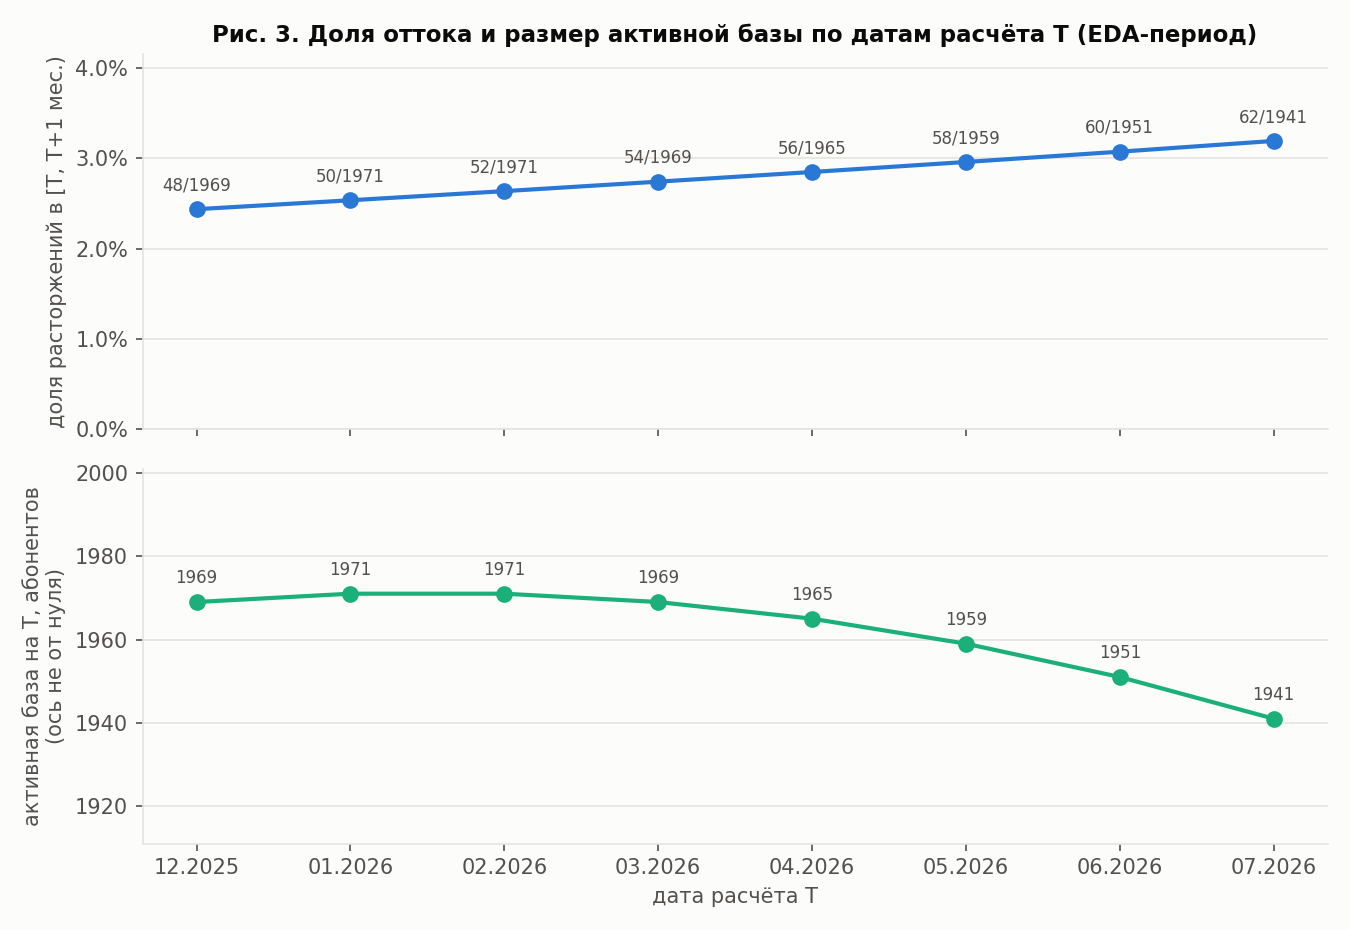

,snapshot_at,n_observations,n_customers,n_churn,churn_rate,small_group,independent_base_size
0,2025-12-01 00:00:00,1969,1969,48,0.02438,0,1969
1,2026-01-01 00:00:00,1971,1971,50,0.02537,0,1971
2,2026-02-01 00:00:00,1971,1971,52,0.02638,0,1971
3,2026-03-01 00:00:00,1969,1969,54,0.02743,0,1969
4,2026-04-01 00:00:00,1965,1965,56,0.02850,0,1965
5,2026-05-01 00:00:00,1959,1959,58,0.02961,0,1959
6,2026-06-01 00:00:00,1951,1951,60,0.03075,0,1951
7,2026-07-01 00:00:00,1941,1941,62,0.03194,0,1941


In [5]:
display(Image(OUT / 'figures' / 'fig3_churn_by_T.png'))
T('fig3_churn_by_T')

## 4. Долг и обращения

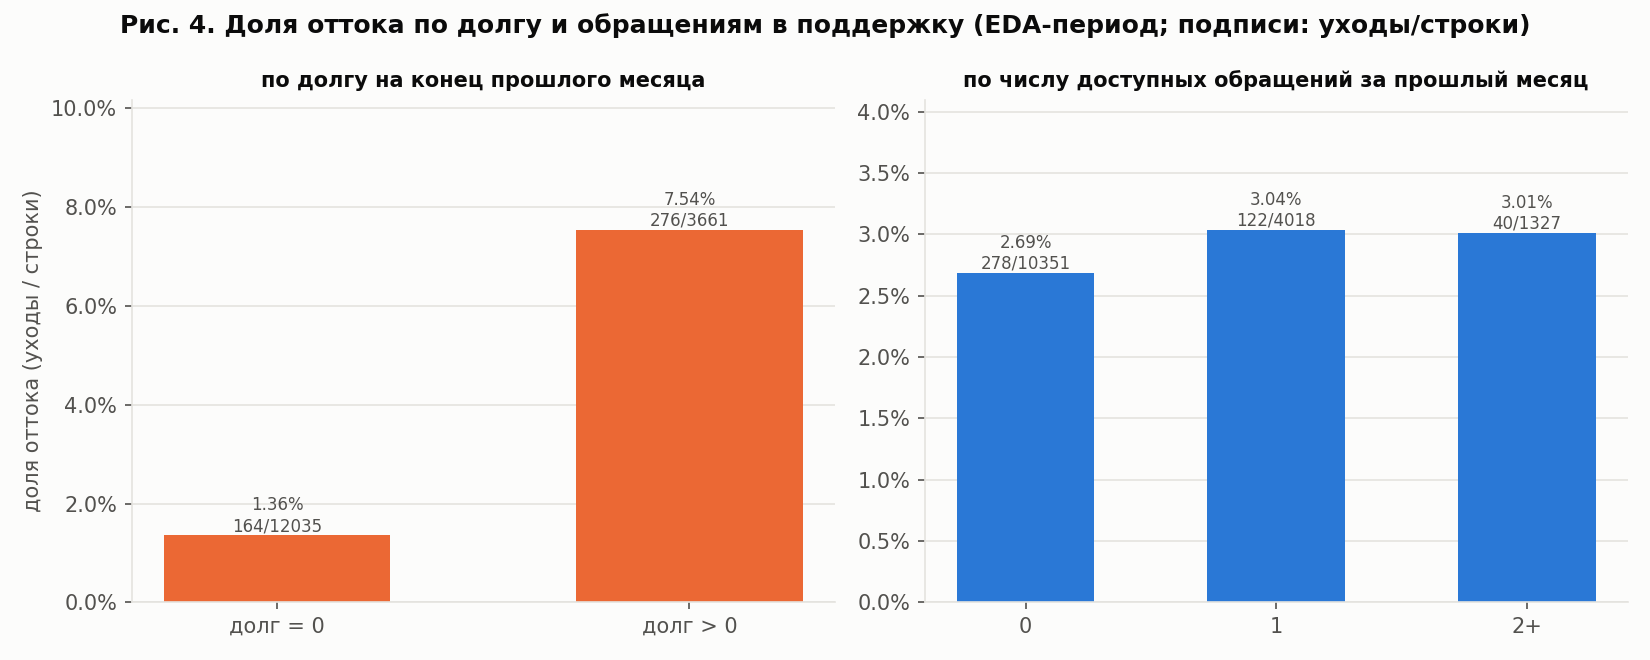

,debt_group,n_observations,n_customers,n_churn,churn_rate,small_group
0,долг = 0,12035,2241,164,0.01363,0
1,долг > 0,3661,1784,276,0.07539,0


,support_group,n_observations,n_customers,n_churn,churn_rate,small_group
0,0,10351,2278,278,0.02686,0
1,1,4018,1867,122,0.03036,0
2,2+,1327,962,40,0.03014,0


In [6]:
display(Image(OUT / 'figures' / 'fig4_debt_support.png'))
display(T('fig4_churn_by_debt'), T('fig4_churn_by_support'))

Проверка альтернативного объяснения: разница по долгу внутри месяцев, тарифов и групп стажа; ДИ — бутстрэп по абонентам (учитывает повторные наблюдения).

In [7]:
display(T('stratified_checks')); T('bootstrap_ci')

,strata,stratum,n_observations__долг = 0,n_observations__долг > 0,n_churn__долг = 0,n_churn__долг > 0,churn_rate__долг = 0,churn_rate__долг > 0,rate_diff,rate_ratio,small_group,n_observations__<90 дн.,n_observations__≥90 дн.,n_churn__<90 дн.,n_churn__≥90 дн.,churn_rate__<90 дн.,churn_rate__≥90 дн.
0,T,2025-12,1514.0,455.0,22.0,26.0,0.01453,0.05714,0.04261,3.933,0,NaN,NaN,NaN,NaN,NaN,NaN
1,T,2026-01,1505.0,466.0,17.0,33.0,0.01130,0.07082,0.05952,6.267,0,NaN,NaN,NaN,NaN,NaN,NaN
2,T,2026-02,1527.0,444.0,22.0,30.0,0.01441,0.06757,0.05316,4.689,0,NaN,NaN,NaN,NaN,NaN,NaN
3,T,2026-03,1520.0,449.0,20.0,34.0,0.01316,0.07572,0.06256,5.754,0,NaN,NaN,NaN,NaN,NaN,NaN
4,T,2026-04,1497.0,468.0,18.0,38.0,0.01202,0.08120,0.06918,6.755,0,NaN,NaN,NaN,NaN,NaN,NaN
5,T,2026-05,1509.0,450.0,18.0,40.0,0.01193,0.08889,0.07696,7.451,0,NaN,NaN,NaN,NaN,NaN,NaN
6,T,2026-06,1459.0,492.0,24.0,36.0,0.01645,0.07317,0.05672,4.448,0,NaN,NaN,NaN,NaN,NaN,NaN
7,T,2026-07,1504.0,437.0,23.0,39.0,0.01529,0.08924,0.07395,5.836,0,NaN,NaN,NaN,NaN,NaN,NaN
8,tariff,Basic,4831.0,1408.0,66.0,89.0,0.01366,0.06321,0.04955,4.627,0,NaN,NaN,NaN,NaN,NaN,NaN
9,tariff,Comfort,4780.0,1506.0,68.0,118.0,0.01423,0.07835,0.06412,5.506,0,NaN,NaN,NaN,NaN,NaN,NaN


,comparison,rate_a,rate_b,diff,ci95_low,ci95_high,n_customers,iterations
0,debt_group: долг > 0 − долг = 0,0.07539,0.01363,0.06176,0.05312,0.07064,2319,1000
1,support_any: 1+ − 0,0.03031,0.02686,0.00345,-0.00175,0.00916,2319,1000
2,tenure_group: <90 дн. − ≥90 дн.,0.03646,0.02740,0.00906,-0.00193,0.02118,2319,1000


## 5. Стаж

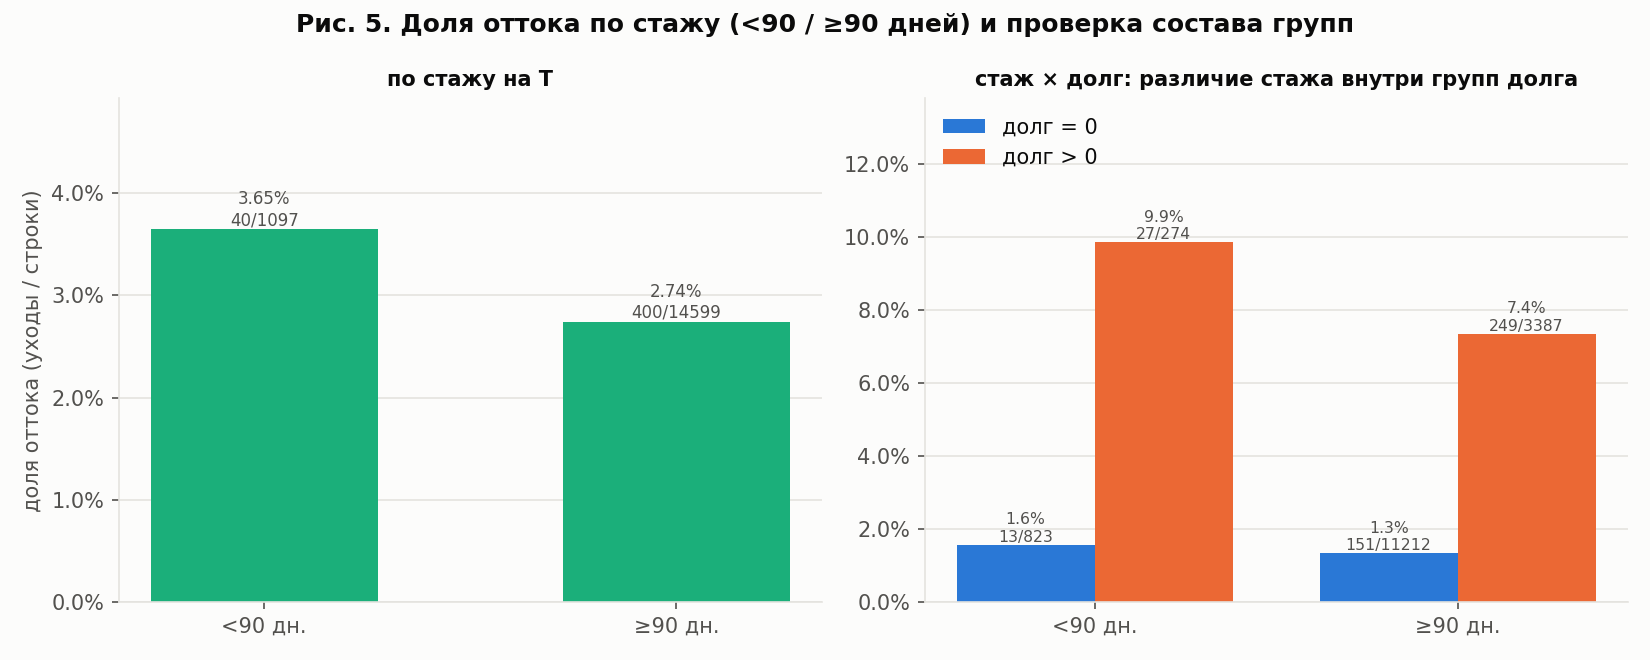

,tenure_group,n_observations,n_customers,n_churn,churn_rate,small_group
0,<90 дн.,1097,445,40,0.03646,0
1,≥90 дн.,14599,2144,400,0.02740,0


,debt_group,tenure_group,n_observations,n_customers,n_churn,churn_rate,small_group
0,долг = 0,<90 дн.,823,402,13,0.01580,0
1,долг = 0,≥90 дн.,11212,2077,151,0.01347,0
2,долг > 0,<90 дн.,274,218,27,0.09854,0
3,долг > 0,≥90 дн.,3387,1656,249,0.07352,0


In [8]:
display(Image(OUT / 'figures' / 'fig5_tenure.png'))
display(T('fig5_churn_by_tenure'), T('fig5_tenure_by_debt'))

## 6. Сеть и контекст

Доля ошибок по нескольким регионам — `sum(failed) / sum(probes)`. На T используется только отчёт с `report_available_at ≤ T`.

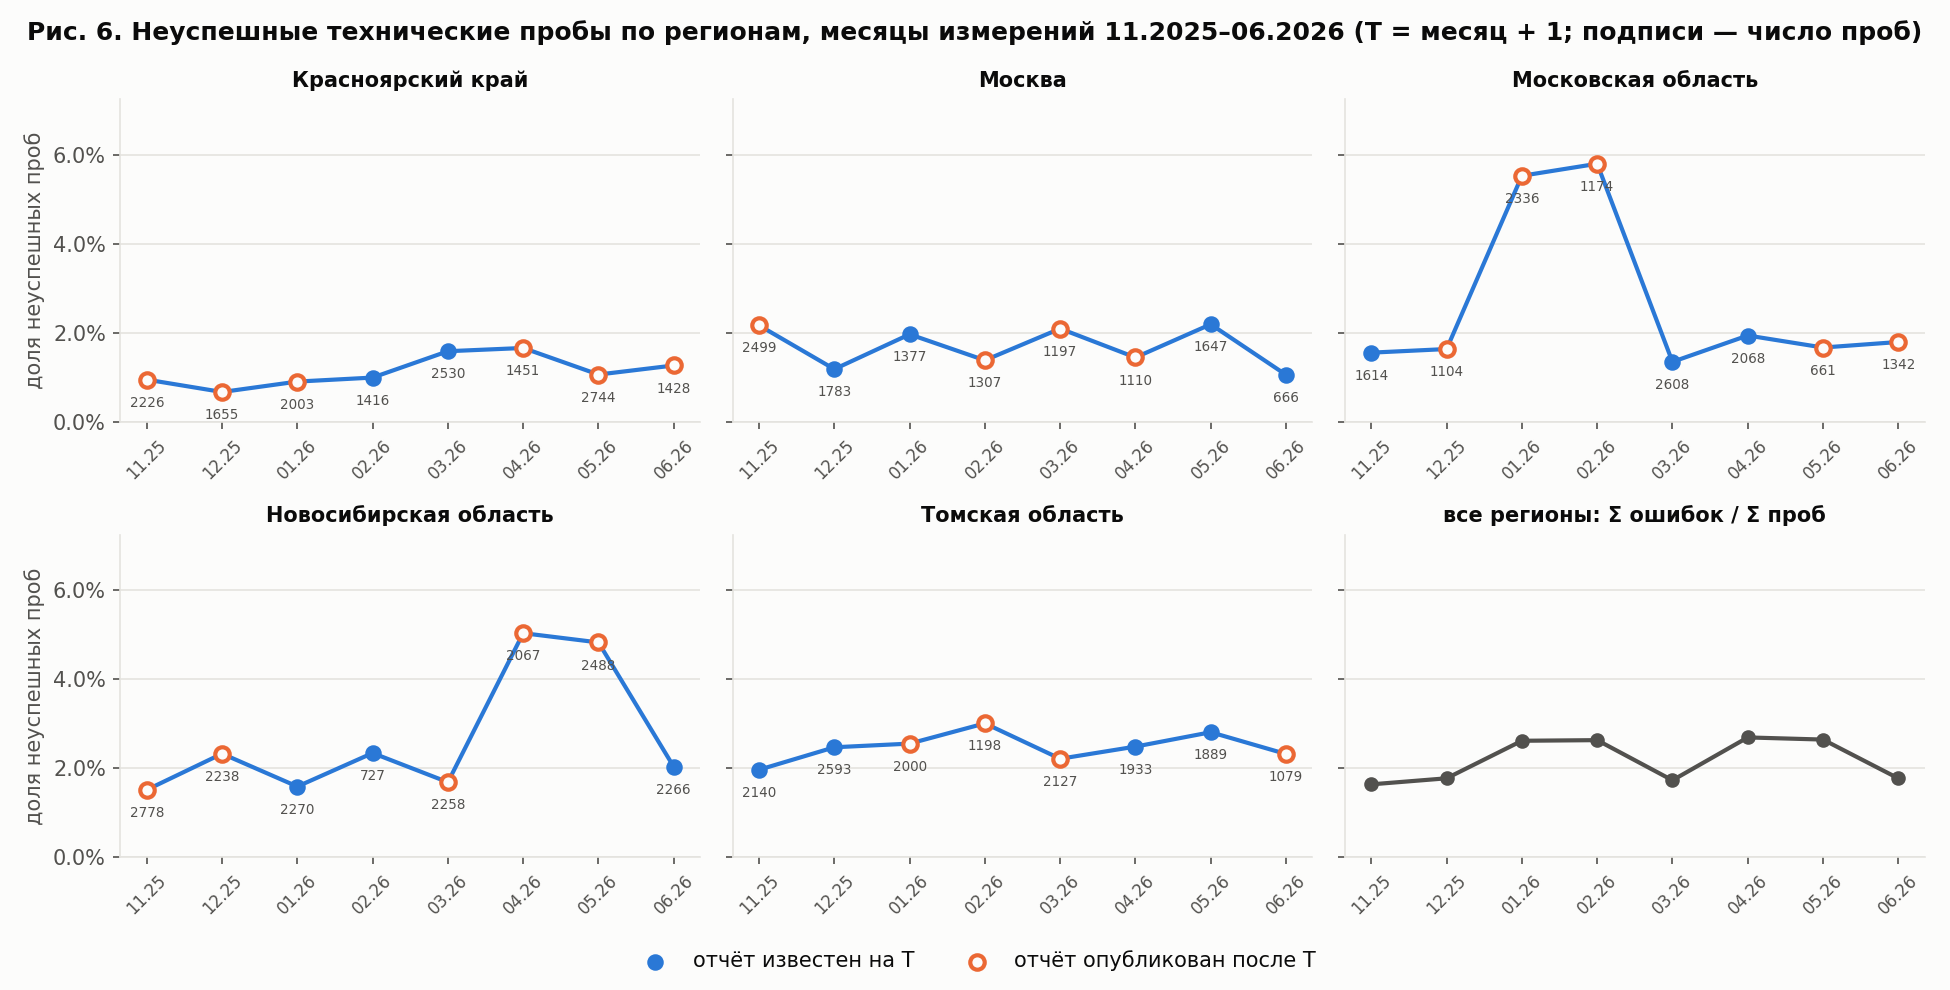

,известно,регионов
snapshot_at,,
2025-12-01 00:00:00,2,5
2026-01-01 00:00:00,2,5
2026-02-01 00:00:00,2,5
2026-03-01 00:00:00,2,5
2026-04-01 00:00:00,2,5
2026-05-01 00:00:00,2,5
2026-06-01 00:00:00,2,5
2026-07-01 00:00:00,2,5
2026-08-01 00:00:00,2,5


,network_group,n_observations,n_customers,n_churn,churn_rate,small_group
0,доля ошибок > 0.0196 (медиана),2773,1282,78,0.02813,0
1,доля ошибок ≤ 0.0196,3536,1701,107,0.03026,0
2,отчёт неизвестен на T,9387,2253,255,0.02717,0


,context_id,event_start,event_end,region,event_type,announced_at_msk,announced_after_period_end,first_T_known
0,B001,2025-11-01,2025-11-01,NaN,support_migration,2025-10-20 12:00:00,0,2025-11-01 00:00:00
1,B002,2026-01-01,2026-01-11,NaN,seasonal_context,2025-12-15 12:00:00,0,2026-01-01 00:00:00
2,B003,2026-01-01,2026-02-28,Московская область,measurement_alert,2026-03-03 12:00:00,1,2026-04-01 00:00:00
3,B004,2026-04-01,2026-05-31,Новосибирская область,measurement_alert,2026-06-03 12:00:00,1,2026-07-01 00:00:00
4,B005,2026-06-01,2026-08-31,NaN,seasonal_context,2026-05-15 12:00:00,0,2026-06-01 00:00:00


In [9]:
display(Image(OUT / 'figures' / 'fig6_network.png'))
av = pd.read_csv(OUT / 'network_availability.csv', sep=';', encoding='utf-8-sig')
display(av.groupby('snapshot_at')['report_known_at_T'].agg(['sum', 'size']).rename(columns={'sum': 'известно', 'size': 'регионов'}))
display(T('churn_by_network_at_T')); T('business_context_timing')[['context_id', 'event_start', 'event_end', 'region', 'event_type', 'announced_at_msk', 'announced_after_period_end', 'first_T_known']]

## Проверки

In [10]:
res['checks']

,check,passed,detail
0,"ключ (customer_id, snapshot_at) уникален",True,19541 строк
1,строк на T = независимо рассчитанная активная ...,True,расхождений: 0
2,billing_available_at ≤ snapshot_at,True,нарушений 0
3,source_billing_month = T − 1 месяц,True,
4,дата будущего расторжения не в признаках,True,поля: нет
5,метка неполного горизонта неизвестна (не 0); в...,True,строк с неизвестной меткой: 0
6,граничный пример: события ровно на T и на конц...,True,boundary_example.csv
7,сетевой отчёт после T неизвестен на T,True,"отчётов, опубликованных после T: 30 из 50"
8,групповые числители и знаменатели восстанавлив...,True,"N = 15696, уходов 440"
9,в EDA не попали валидация/тест,True,8 дат T
